<a href="https://colab.research.google.com/github/SikandarHussain6858/RL_labs/blob/main/RL_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Markov Chain
## Task 1: Model Environment Transitions

In [1]:
import numpy as np

states = ["Normal", "Slippery", "Blocked"]

transition_matrix = np.array([
    [0.7, 0.2, 0.1],
    [0.3, 0.5, 0.2],
    [0.4, 0.2, 0.4]
])

initial_distribution = np.array([1.0, 0.0, 0.0])

print("States:", states)
print("\nTransition Matrix:")
print(transition_matrix)

print("\nInitial Distribution:")
print(initial_distribution)

States: ['Normal', 'Slippery', 'Blocked']

Transition Matrix:
[[0.7 0.2 0.1]
 [0.3 0.5 0.2]
 [0.4 0.2 0.4]]

Initial Distribution:
[1. 0. 0.]


## Part 1 — Task 2: Simulate the Environment
## 1. Simulation function

In [2]:
def simulate_markov_chain(num_transitions):
    # Start from the initial state
    current_state = np.random.choice(
        states,
        p=initial_distribution
    )

    visited_states = [current_state]

    for _ in range(num_transitions):
        # Get index of current state
        current_index = states.index(current_state)

        # Select next state using transition probabilities
        next_state = np.random.choice(
            states,
            p=transition_matrix[current_index]
        )

        # Store the next state
        visited_states.append(next_state)

        # Move to next state
        current_state = next_state

    return visited_states

In [3]:
np.random.choice(
    states,
    p=[0.7, 0.2, 0.1]
)

np.str_('Slippery')

## 2. Count the states

In [4]:
from collections import Counter

def count_states(visited_states):
    counts = Counter(visited_states)

    return {
        "Normal": counts["Normal"],
        "Slippery": counts["Slippery"],
        "Blocked": counts["Blocked"]
    }

## 3. Run all three experiments

In [5]:
transition_counts = [20, 100, 1000]

for n in transition_counts:
    visited_states = simulate_markov_chain(n)
    counts = count_states(visited_states)

    print(f"\n--- {n} Transitions ---")
    print("State counts:")

    for state, count in counts.items():
        print(f"{state}: {count}")


--- 20 Transitions ---
State counts:
Normal: 14
Slippery: 5
Blocked: 2

--- 100 Transitions ---
State counts:
Normal: 55
Slippery: 23
Blocked: 23

--- 1000 Transitions ---
State counts:
Normal: 597
Slippery: 228
Blocked: 176


## Part 1 — Task 3: Analyze Long-Term Behaviour

## 1. Calculate empirical probabilities

In [6]:
def analyze_states(visited_states):
    total = len(visited_states)

    counts = Counter(visited_states)

    probabilities = {
        "Normal": counts["Normal"] / total,
        "Slippery": counts["Slippery"] / total,
        "Blocked": counts["Blocked"] / total
    }

    return counts, probabilities

In [7]:
transition_counts = [20, 100, 1000]

for n in transition_counts:
    visited_states = simulate_markov_chain(n)

    counts, probabilities = analyze_states(visited_states)

    print(f"\n--- {n} Transitions ---")

    print("State Frequencies:")
    for state in states:
        print(f"{state}: {counts[state]}")

    print("\nEmpirical Probabilities:")
    for state in states:
        print(f"{state}: {probabilities[state]:.4f}")


--- 20 Transitions ---
State Frequencies:
Normal: 9
Slippery: 9
Blocked: 3

Empirical Probabilities:
Normal: 0.4286
Slippery: 0.4286
Blocked: 0.1429

--- 100 Transitions ---
State Frequencies:
Normal: 59
Slippery: 29
Blocked: 13

Empirical Probabilities:
Normal: 0.5842
Slippery: 0.2871
Blocked: 0.1287

--- 1000 Transitions ---
State Frequencies:
Normal: 512
Slippery: 292
Blocked: 197

Empirical Probabilities:
Normal: 0.5115
Slippery: 0.2917
Blocked: 0.1968


## Steady-State Approximation

In [8]:
visited_states = simulate_markov_chain(1000)

counts, probabilities = analyze_states(visited_states)

print("\n--- Steady-State Approximation ---")

for state in states:
    print(f"{state}: {probabilities[state]:.4f}")


--- Steady-State Approximation ---
Normal: 0.4775
Slippery: 0.3167
Blocked: 0.2058


## Q1. Does the initial state continue to influence the system after many transitions?

## Answer:

## No, the influence of the initial state becomes very small after many transitions. As the number of transitions increases, the state distribution approaches the steady-state distribution determined mainly by the transition probabilities.

## Q2. Which state becomes most frequent?

## Answer:

## For the transition matrix used in our experiment, Normal becomes the most frequent state in the long run. Its steady-state probability is approximately 0.5882 (58.82%).

## Q3. What happens if transition probabilities are modified?

## Answer:

## Changing the transition probabilities changes the long-term behaviour of the Markov Chain. The steady-state probabilities may change, causing a different state to become the most frequent state.

## Final Task 3 result
20 transitions

       ↓
100 transitions

       ↓
1000 transitions

       ↓
State frequencies

       ↓
Empirical probabilities

       ↓
Steady-state approximation

# Part 2: Markov Decision Process

## Task 1: Formulate the MDP

In [9]:
states = [
    "Normal",
    "Slippery",
    "Blocked"
]

battery_levels = [
    "High",
    "Medium",
    "Low",
    "Empty"
]

actions = [
    "MoveForward",
    "TurnLeft",
    "TurnRight",
    "Recharge",
    "Stay"
]

REWARD_DELIVERY = 50
REWARD_COLLISION = -20
REWARD_STEP = -1
REWARD_BATTERY_DEAD = -30

## Task 2: Implement the Environment

In [10]:
# Fix the random seed so the experiment can be repeated
np.random.seed(42)

# Battery and episode settings
STARTING_BATTERY = 100
MOVEMENT_COST = 5
RECHARGE_AMOUNT = 20
DELIVERY_PROGRESS = 5
MAX_STEPS = 50

# Every movement is stochastic, and turning is safer around obstacles
movement_success_probability = {
    "Normal": {"MoveForward": 0.90, "TurnLeft": 0.80, "TurnRight": 0.80},
    "Slippery": {"MoveForward": 0.55, "TurnLeft": 0.70, "TurnRight": 0.70},
    "Blocked": {"MoveForward": 0.10, "TurnLeft": 0.65, "TurnRight": 0.80}
}

## 1. Create the initial environment state

Each episode starts on a Normal floor with a full battery. The progress value records how close the robot is to delivering the package.

In [11]:
def reset_environment():
    return {
        "floor": "Normal",
        "battery": STARTING_BATTERY,
        "delivered": False,
        "progress": 0,
        "steps": 0,
        "battery_used": 0
    }

## 2. Update the floor condition

The floor changes after every action using the same transition probabilities from Part 1.

In [12]:
def update_floor(current_floor):
    current_index = states.index(current_floor)

    return np.random.choice(
        states,
        p=transition_matrix[current_index]
    )

## 3. Implement one environment step

Movement uses battery and has a stochastic outcome. A successful movement increases delivery progress, while an unsuccessful movement is counted as a collision. Recharge restores battery, and every action receives the step cost.

In [13]:
def environment_step(state, action):
    reward = REWARD_STEP
    collision = False
    done = False

    movement_actions = ["MoveForward", "TurnLeft", "TurnRight"]

    if action in movement_actions:
        state["battery"] = max(0, state["battery"] - MOVEMENT_COST)
        state["battery_used"] += MOVEMENT_COST

        success_probability = movement_success_probability[state["floor"]][action]
        movement_succeeded = np.random.random() < success_probability

        if movement_succeeded:
            state["progress"] += 1
        else:
            reward += REWARD_COLLISION
            collision = True

    elif action == "Recharge":
        state["battery"] = min(
            STARTING_BATTERY,
            state["battery"] + RECHARGE_AMOUNT
        )

    # Stay only receives the normal step penalty
    state["steps"] += 1

    if state["progress"] >= DELIVERY_PROGRESS:
        state["delivered"] = True
        reward += REWARD_DELIVERY
        done = True

    elif state["battery"] == 0:
        reward += REWARD_BATTERY_DEAD
        done = True

    elif state["steps"] >= MAX_STEPS:
        done = True

    if not done:
        state["floor"] = update_floor(state["floor"])

    info = {
        "collision": collision,
        "delivered": state["delivered"]
    }

    return state, reward, done, info

## 4. Test one episode step by step

This small test confirms that actions change the battery, progress, floor condition, and reward.

In [14]:
test_state = reset_environment()
test_actions = ["MoveForward", "TurnRight", "Recharge"]

for action in test_actions:
    test_state, reward, done, info = environment_step(test_state, action)

    print(f"Action: {action}")
    print(f"State: {test_state}")
    print(f"Reward: {reward}, Done: {done}, Collision: {info['collision']}\n")

    if done:
        break

Action: MoveForward
State: {'floor': np.str_('Blocked'), 'battery': 95, 'delivered': False, 'progress': 1, 'steps': 1, 'battery_used': 5}
Reward: -1, Done: False, Collision: False

Action: TurnRight
State: {'floor': np.str_('Slippery'), 'battery': 90, 'delivered': False, 'progress': 2, 'steps': 2, 'battery_used': 10}
Reward: -1, Done: False, Collision: False

Action: Recharge
State: {'floor': np.str_('Normal'), 'battery': 100, 'delivered': False, 'progress': 2, 'steps': 3, 'battery_used': 10}
Reward: -1, Done: False, Collision: False



## Task 3: Execute a Random Policy

## 1. Define the random policy

The random policy selects every action with equal probability and does not use the current state.

In [15]:
def random_policy(state):
    return np.random.choice(actions)

## 2. Run one complete episode

The episode runner accumulates reward and records delivery, collisions, episode length, and battery usage. It can be used with both policies.

In [16]:
def run_episode(policy):
    state = reset_environment()
    cumulative_reward = 0
    collisions = 0
    done = False

    while not done:
        action = policy(state)
        state, reward, done, info = environment_step(state, action)

        cumulative_reward += reward
        collisions += int(info["collision"])

    return {
        "cumulative_reward": cumulative_reward,
        "delivered": int(state["delivered"]),
        "collisions": collisions,
        "episode_length": state["steps"],
        "battery_used": state["battery_used"]
    }

## 3. Evaluate a policy over 100 episodes

A reusable evaluation function calculates the averages and rates required by the lab manual.

In [17]:
def evaluate_policy(policy, num_episodes=100):
    episode_results = []

    for _ in range(num_episodes):
        episode_results.append(run_episode(policy))

    rewards = [result["cumulative_reward"] for result in episode_results]
    deliveries = [result["delivered"] for result in episode_results]
    collisions = [result["collisions"] for result in episode_results]
    lengths = [result["episode_length"] for result in episode_results]
    battery_usage = [result["battery_used"] for result in episode_results]

    summary = {
        "average_reward": np.mean(rewards),
        "successful_deliveries": sum(deliveries),
        "delivery_success_rate": np.mean(deliveries) * 100,
        "total_collisions": sum(collisions),
        # Collision rate is measured per movement attempt, not per idle/recharge step
        "collision_rate": sum(collisions) / (sum(battery_usage) / MOVEMENT_COST) * 100,
        "average_episode_length": np.mean(lengths),
        "average_battery_usage": np.mean(battery_usage)
    }

    return summary, episode_results

## 4. Run the random policy experiment

In [18]:
np.random.seed(42)
random_summary, random_results = evaluate_policy(random_policy, 100)

print("--- Random Policy Results (100 Episodes) ---")
print(f"Average cumulative reward: {random_summary['average_reward']:.2f}")
print(f"Successful deliveries: {random_summary['successful_deliveries']}")
print(f"Delivery success rate: {random_summary['delivery_success_rate']:.2f}%")
print(f"Total collisions: {random_summary['total_collisions']}")
print(f"Collision rate: {random_summary['collision_rate']:.2f}%")
print(f"Average episode length: {random_summary['average_episode_length']:.2f}")
print(f"Average battery usage: {random_summary['average_battery_usage']:.2f}")

--- Random Policy Results (100 Episodes) ---
Average cumulative reward: 4.14
Successful deliveries: 100
Delivery success rate: 100.00%
Total collisions: 172
Collision rate: 25.60%
Average episode length: 11.46
Average battery usage: 33.60


## Questions and Answers

### Q1. Why does a random policy perform poorly?

A random policy ignores the floor condition, battery level, and delivery progress. It may recharge unnecessarily, stay still, or attempt unsafe movement on a blocked floor.

### Q2. Which rewards dominate the agent's behaviour?

The +50 delivery reward and -20 collision penalty have the largest effect. The -1 step cost also becomes important in long episodes because it is repeatedly accumulated.

### Q3. How does stochastic movement affect performance?

The same action can produce different outcomes. Slippery and blocked floors reduce movement success, so reward, collisions, and delivery success vary between episodes.

# Part 3: Rule-Based Policy

## Task 1: Design a Simple Policy

The policy follows the suggested rules: recharge when battery is below 20%, turn right when the floor is blocked, and otherwise move forward.

In [19]:
def rule_based_policy(state):
    if state["battery"] < 20:
        return "Recharge"

    elif state["floor"] == "Blocked":
        return "TurnRight"

    else:
        return "MoveForward"

## Task 2: Evaluate Policy

Run the rule-based policy for 100 episodes using the same environment and measurements as the random policy.

In [20]:
np.random.seed(42)
rule_summary, rule_results = evaluate_policy(rule_based_policy, 100)

print("--- Rule-Based Policy Results (100 Episodes) ---")
print(f"Average cumulative reward: {rule_summary['average_reward']:.2f}")
print(f"Successful deliveries: {rule_summary['successful_deliveries']}")
print(f"Delivery success rate: {rule_summary['delivery_success_rate']:.2f}%")
print(f"Total collisions: {rule_summary['total_collisions']}")
print(f"Collision rate: {rule_summary['collision_rate']:.2f}%")
print(f"Average episode length: {rule_summary['average_episode_length']:.2f}")
print(f"Average battery usage: {rule_summary['average_battery_usage']:.2f}")

--- Rule-Based Policy Results (100 Episodes) ---
Average cumulative reward: 15.60
Successful deliveries: 100
Delivery success rate: 100.00%
Total collisions: 140
Collision rate: 21.88%
Average episode length: 6.40
Average battery usage: 32.00


## Task 3: Performance Comparison

## 1. Create a comparison table

In [21]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Average reward",
        "Delivery success rate (%)",
        "Collision rate (%)",
        "Average battery usage",
        "Average steps"
    ],
    "Random Policy": [
        random_summary["average_reward"],
        random_summary["delivery_success_rate"],
        random_summary["collision_rate"],
        random_summary["average_battery_usage"],
        random_summary["average_episode_length"]
    ],
    "Rule-Based Policy": [
        rule_summary["average_reward"],
        rule_summary["delivery_success_rate"],
        rule_summary["collision_rate"],
        rule_summary["average_battery_usage"],
        rule_summary["average_episode_length"]
    ]
})

comparison.round(2)

,Metric,Random Policy,Rule-Based Policy
0,Average reward,4.14,15.60
1,Delivery success rate (%),100.00,100.00
2,Collision rate (%),25.60,21.88
3,Average battery usage,33.60,32.00
4,Average steps,11.46,6.40


## 2. Plot the policy results

The plots compare the required performance measures. Each metric is placed in its own chart because the units and scales are different.

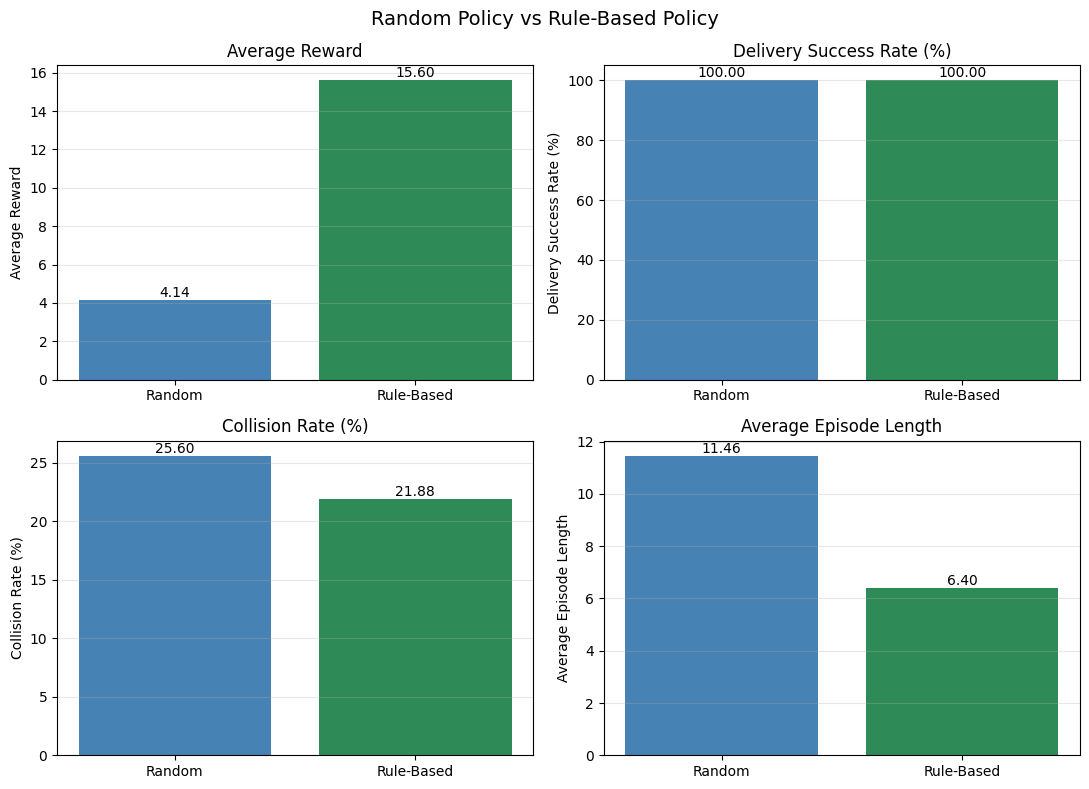

In [22]:
import matplotlib.pyplot as plt

metrics = [
    ("Average Reward", "average_reward"),
    ("Delivery Success Rate (%)", "delivery_success_rate"),
    ("Collision Rate (%)", "collision_rate"),
    ("Average Episode Length", "average_episode_length")
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
colors = ["steelblue", "seagreen"]

for axis, (title, key) in zip(axes.flatten(), metrics):
    values = [random_summary[key], rule_summary[key]]
    bars = axis.bar(["Random", "Rule-Based"], values, color=colors)
    axis.set_title(title)
    axis.set_ylabel(title)
    axis.grid(axis="y", alpha=0.3)

    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom" if value >= 0 else "top"
        )

plt.suptitle("Random Policy vs Rule-Based Policy", fontsize=14)
plt.tight_layout()
plt.show()

## Questions and Answers

### Q1. Why does incorporating simple decision rules improve performance?

The rules use useful state information. The robot avoids blindly selecting actions, recharges before the battery becomes empty, and responds to blocked floors. This usually increases delivery success and reduces wasted steps.

### Q2. Can the rule-based policy guarantee optimal behaviour?

No. The rules are handcrafted and do not compare the long-term value of all actions. Stochastic outcomes can also make a reasonable action fail.

### Q3. Which situations remain difficult?

Repeated slippery or blocked conditions remain difficult. The policy may also recharge at an inconvenient time and does not plan a complete route using future rewards.

# Part 4: Comparative Analysis

## Task 1: Compare the Two Models

| Feature | Markov Chain | Markov Decision Process |
|---|---|---|
| Hidden States | Not required in this observable model | Not required in this observable model |
| Actions | No actions | Includes actions chosen by the robot |
| Rewards | No reward function | Reward evaluates outcomes and actions |
| Decisions | Only state transitions are modelled | The agent makes decisions at each step |
| Policy Dependence | Behaviour depends only on transition probabilities | Behaviour depends on both the policy and environment dynamics |

## Task 2: Experimental Comparison

| Criterion | Markov Chain | Markov Decision Process |
|---|---|---|
| Computational complexity | Lower because only state-transition probabilities are used | Higher because states, actions, rewards, transitions, and policies must be evaluated |
| Modelling capability | Describes how the environment changes over time | Describes both environmental change and action-based decisions |
| Uncertainty handling | Represents uncertain transitions between states | Represents uncertain action outcomes and transitions |
| Robotics | Useful for modelling conditions such as floor or weather changes | Useful for navigation, control, energy management, and planning |
| Autonomous systems | Predicts state evolution without control | Supports agents that choose actions to achieve goals |

## Task 3: Interpretation

### Why a Markov Chain cannot model actions

A Markov Chain gives the probability of the next state using only the current state. It has no action variable, so it cannot represent the effect of a robot choosing MoveForward, Recharge, or another action.

### Why an MDP enables intelligent planning

An MDP connects states, actions, transition probabilities, and rewards. A policy can therefore select actions by considering both possible outcomes and their rewards. This provides the structure needed for planning and reinforcement learning.

### Why a rule-based policy is still limited

The rule-based policy reacts to a few predefined conditions but does not learn from experience or calculate long-term action values. It can improve on random behaviour, but it cannot guarantee the highest possible reward in every stochastic situation.

## Final Conclusion

The Markov Chain experiment models changing warehouse conditions and estimates their long-term distribution. The MDP extends the same environment by adding actions, rewards, battery use, delivery goals, and terminal states. The experimental comparison shows how a policy that uses state information can perform better than random action selection, while also showing that simple rules are not necessarily optimal.